# **Część A**: n-gramy w tekście polskim
### Opis Zadania
1. Pobierz wybraną książkę w formacie .txt i wczytaj ją w Pythonie.
2. Oczyść tekst: usuń znaki specjalne, zamień litery na małe, zwiń wielokrotne białe znaki.
3. Wykonaj tokenizację na zdania i na wyrazy. Podaj, ile zdań i ile wyrazów ma tekst.
4. Wygeneruj unigramy, bigramy i trigramy słowne.
5. Policz częstość występowania n-gramów (collections.Counter albo nltk).
6. Narysuj histogramy dziesięciu najczęstszych bigramów i dziesięciu najczęstszych trigramów (matplotlib).
7. Odpowiedz w komentarzu w kodzie lub w pliku tekstowym na pytania:
– Jakie bigramy dominują w analizowanym tekście?
– Czy trigramy pokazują powtarzalne zwroty charakterystyczne dla autora?
– Jak różni się rozkład unigramów od rozkładu bigramów?
Punkt wyjścia: example_16.py i example_17.py z materiałów do wykładu.

Liczba zdań: 1
Liczba wyrazów: 68422
Unigramy: 68422
Bigramy: 68421
Trigramy: 68420

10 najczęstszych unigramów:
('i',) 2134
('w',) 1699
('się',) 1498
('z',) 1389
('na',) 1309
('nie',) 938
('jak',) 579
('do',) 566
('a',) 565
('że',) 555

10 najczęstszych bigramów:
('się', 'w') 76
('i', 'z') 72
('się', 'z') 68
('się', 'i') 61
('i', 'w') 55
('się', 'na') 47
('i', 'na') 39
('co', 'się') 38
('i', 'tak') 36
('na', 'to') 30

10 najczęstszych trigramów:
('się', 'z', 'nim') 8
('hejże', 'na', 'soplicę') 6
('idąc', 'kłaniał', 'się') 5
('za', 'mych', 'czasów') 5
('ostatniego', 'z', 'horeszków') 5
('z', 'drugiej', 'strony') 5
('raz', 'po', 'raz') 5
('a', 'na', 'to') 5
('pro', 'publico', 'bono') 5
('w', 'domu', 'sędziego') 4


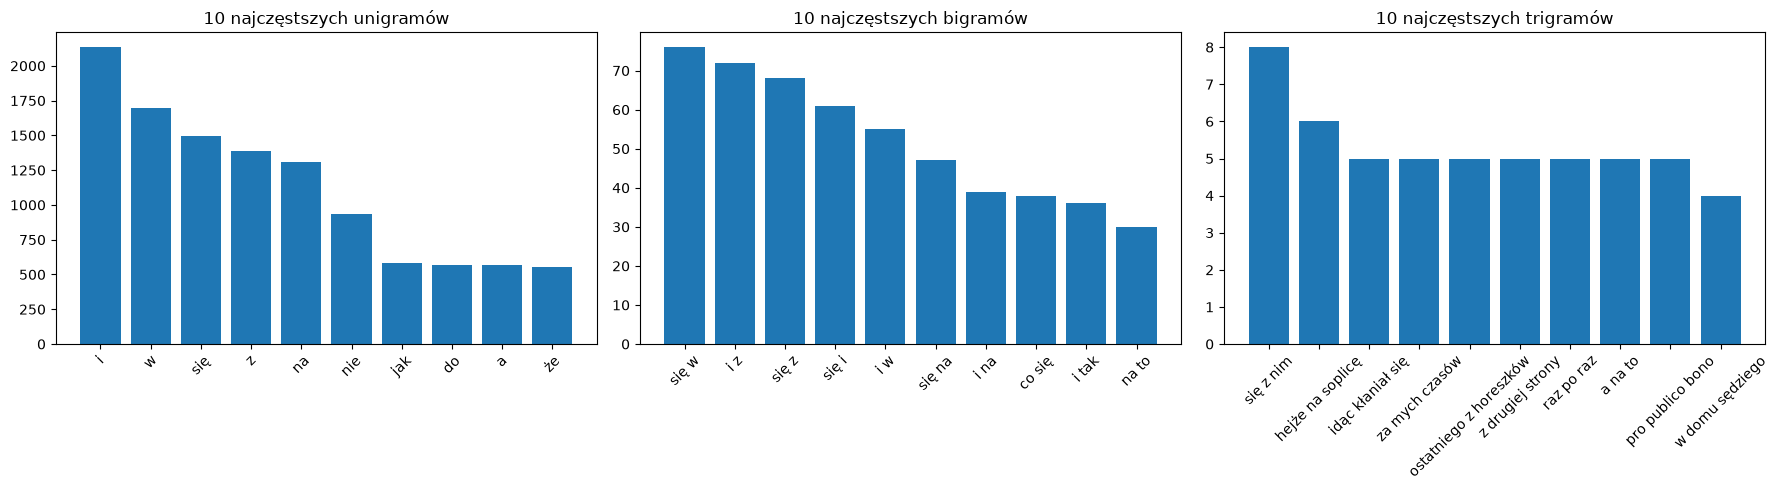

In [1]:
import re
from collections import Counter

import nltk
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.util import ngrams

import matplotlib.pyplot as plt

# --------------------------------------------------
# Wczytanie pliku
# --------------------------------------------------

with open("texts/pan-tadeusz-adam-mickiewicz.txt", "r", encoding="utf-8") as f:
# with open("texts/rozmyslania-marek-aureliusz.txt", "r", encoding="utf-8") as f:
    text = f.read()

# --------------------------------------------------
# Czyszczenie tekstu
# --------------------------------------------------

# małe litery
text = text.lower()

# usunięcie znaków specjalnych
text = re.sub(r"[^\w\s]", " ", text)

# zwinięcie wielokrotnych białych znaków
text = re.sub(r"\s+", " ", text).strip()

# --------------------------------------------------
# Tokenizacja
# --------------------------------------------------

words = word_tokenize(text, language="english")
sentences = sent_tokenize(text)

print(f"Liczba zdań: {len(sentences)}")
print(f"Liczba wyrazów: {len(words)}")

# --------------------------------------------------
# Generowanie n-gramów
# --------------------------------------------------

unigrams = list(ngrams(words, 1))
bigrams = list(ngrams(words, 2))
trigrams = list(ngrams(words, 3))

print(f"Unigramy: {len(unigrams)}")
print(f"Bigramy: {len(bigrams)}")
print(f"Trigramy: {len(trigrams)}")

# --------------------------------------------------
# Liczenie częstości
# --------------------------------------------------

unigram_freq = Counter(unigrams)
bigram_freq = Counter(bigrams)
trigram_freq = Counter(trigrams) 

print("\n10 najczęstszych unigramów:")
top_unigrams = unigram_freq.most_common(10)
for unigram, count in top_unigrams:
    print(unigram, count)

print("\n10 najczęstszych bigramów:")
top_bigrams = bigram_freq.most_common(10)
for bigram, count in top_bigrams:
    print(bigram, count)

print("\n10 najczęstszych trigramów:")
top_trigrams = trigram_freq.most_common(10)
for trigram, count in top_trigrams:
    print(trigram, count)


# --------------------------------------------------
# Histogramy n-gramów
# --------------------------------------------------

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# --------------------------------------------------
# Unigramy
# --------------------------------------------------

labels_ug = [unigram[0] for unigram, _ in top_unigrams]
values_ug = [count for _, count in top_unigrams]

axes[0].bar(labels_ug, values_ug)
axes[0].set_title("10 najczęstszych unigramów")
axes[0].tick_params(axis="x", rotation=45)

# --------------------------------------------------
# Bigramy
# --------------------------------------------------

labels_bg = [" ".join(bigram) for bigram, _ in top_bigrams]
values_bg = [count for _, count in top_bigrams]

axes[1].bar(labels_bg, values_bg)
axes[1].set_title("10 najczęstszych bigramów")
axes[1].tick_params(axis="x", rotation=45)

# --------------------------------------------------
# Trigramy
# --------------------------------------------------

labels_tg = [" ".join(trigram) for trigram, _ in top_trigrams]
values_tg = [count for _, count in top_trigrams]

axes[2].bar(labels_tg, values_tg)
axes[2].set_title("10 najczęstszych trigramów")
axes[2].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()


# ------------------  WNIOSKI ---------------------



# **Część B**: sprowadzanie form w tekście angielskim
### Opis Zadania
1. Pobierz tekst z literatury angielskiej (np. Hamlet z Project Gutenberg).
2. Wybierz z niego 5 zdań.
3. Dla tych zdań wykonaj tokenizację, stemming (jeden algorytm) i lematyzację (jeden algorytm).
4. Zestaw wyniki w tabeli: token → rdzeń → lemat. Wskaż co najmniej trzy słowa, dla których stemming i
lematyzacja dały różne wyniki.
Punkt wyjścia: example_08.py i example_09.py.

In [10]:
import nltk

# nltk.download("punkt")
# nltk.download("wordnet")
# nltk.download("omw-1.4")

from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.stem import SnowballStemmer, WordNetLemmatizer

# --------------------------------------------------
# Wczytanie tekstu
# --------------------------------------------------

with open("texts/hamlet-william-shakespeare.txt", "r", encoding="utf-8") as f:
    text = f.read()

# --------------------------------------------------
# Pierwsze 5 zdań
# --------------------------------------------------

sentences = sent_tokenize(text)[:5]

stemmer = SnowballStemmer("english")
lemmatizer = WordNetLemmatizer()

print("WYBRANE ZDANIA:\n")

for i, s in enumerate(sentences, start=1):
    print(f"{i}. {s}")

for number, sentence in enumerate(sentences, start=1):

    tokens = word_tokenize(sentence)

    print(f"\n\nZDANIE NUMER {number}:")

    h1, h2, h3 = "TOKEN", "RDZEŃ", "LEMAT"
    print("=" * 53)
    print(f"|{h1:^15} | {h2:^15} | {h3:^15}|")
    print("=" * 53)

    for token in tokens:

        # pomijanie znaków interpunkcyjnych
        if not token.isalpha():
            continue

        stem = stemmer.stem(token.lower())
        lemma = lemmatizer.lemmatize(token.lower())

        print(f"|{token:^15} | {stem:^15} | {lemma:^15}|")
        print("-" * 53)

WYBRANE ZDANIA:

1. The Project Gutenberg eBook of Hamlet
    
This eBook is for the use of anyone anywhere in the United States and
most other parts of the world at no cost and with almost no restrictions
whatsoever.
2. You may copy it, give it away or re-use it under the terms
of the Project Gutenberg License included with this eBook or online
at www.gutenberg.org.
3. If you are not located in the United States,
you will have to check the laws of the country where you are located
before using this eBook.
4. Title: Hamlet

Author: William Shakespeare

Editor: Charles John Kean


        
Release date: January 10, 2009 [eBook #27761]
                Most recently updated: September 9, 2025

Language: English

Other information and formats: www.gutenberg.org/ebooks/27761

Credits: Produced by David Starner, Curtis Weyant and the Online
        Distributed Proofreading Team at https://www.pgdp.net


*** START OF THE PROJECT GUTENBERG EBOOK HAMLET ***




    Transcriber's Note:
    This 